# LLM index

In [1]:
import torch
import matplotlib.pyplot as plt
from datetime import timedelta

from llm_index.data import load_data
from llm_index.compute import fit

### Data

In [2]:
data = load_data()

print(f"{len(data.models)} models, {len(data.benchmarks)} benchmarks, {len(data.milestones)} milestones, {len(data.get_normalized_results())} non-null results")

34 models, 8 benchmarks, 6 milestones, 297 non-null results


### Compute

In [3]:
output = fit(data)

print()
print(f"final loss : {output.loss:.4f}")

epoch 0 | loss = 0.2105057
epoch 5,000 | loss = 0.0038281
epoch 10,000 | loss = 0.0038346
epoch 15,000 | loss = 0.0005951
epoch 20,000 | loss = 0.0005949
epoch 25,000 | loss = 0.0005954
epoch 30,000 | loss = 0.0005949
epoch 35,000 | loss = 0.0005948
epoch 40,000 | loss = 0.0005949
epoch 45,000 | loss = 0.0005948
epoch 49,999 | loss = 0.0005948

final loss : 0.0006


### Results

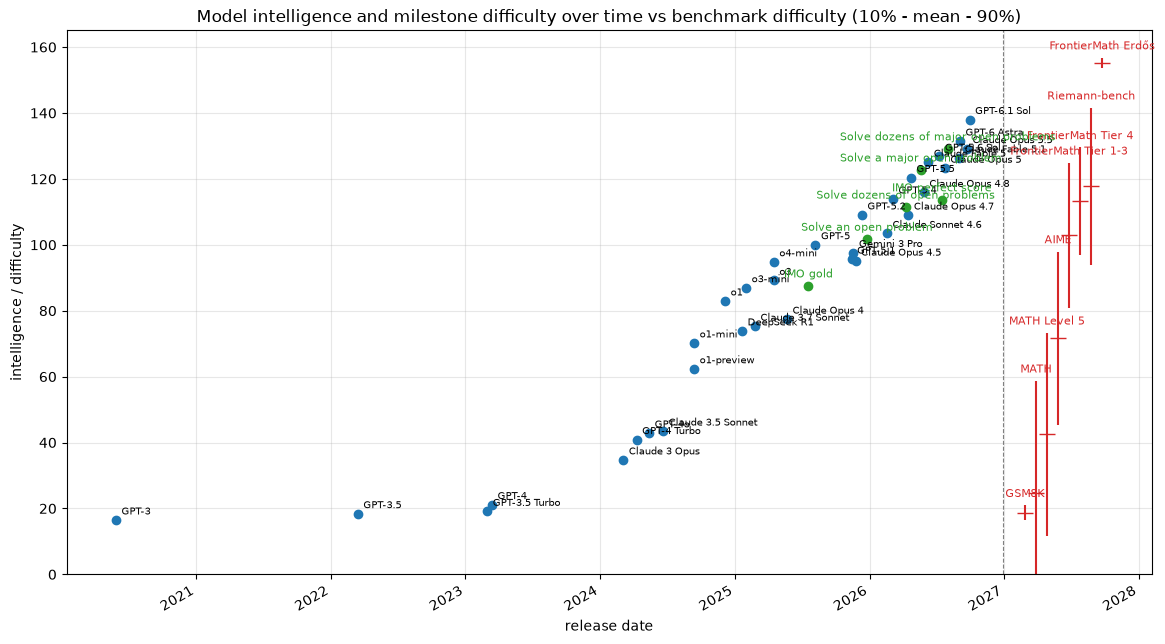

In [4]:
model_ids = list(data.models)
dates = [data.models[id].release_date for id in model_ids]
scores = [output.model_intelligences[id] for id in model_ids]

benchmark_ids = list(output.benchmark_difficulty_means)
milestone_ids = list(output.milestone_difficulties)
benchmark_x0 = max(dates) + timedelta(days=150)

fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(dates, scores, 'o', color='tab:blue')

for id, x, y in zip(model_ids, dates, scores):
	ax.annotate(data.models[id].name, (x, y), textcoords='offset points', xytext=(4, 4), fontsize=7)

bottom_10p_std = torch.distributions.Normal(0, 1).icdf(torch.tensor(0.1)).item()

for i, id in enumerate(benchmark_ids):
	mean = output.benchmark_difficulty_means[id]
	std = output.benchmark_difficulty_stds[id]
	low = mean + bottom_10p_std * std
	high = mean - bottom_10p_std * std
	x = benchmark_x0 + timedelta(days=30 * i)

	ax.vlines(x, low, high, color='tab:red', linewidth=1.5)
	ax.plot([x], [mean], marker='_', markersize=12, color='tab:red')
	ax.annotate(data.benchmarks[id].name, (x, high), textcoords='offset points', xytext=(0, 6), fontsize=8, color='tab:red', ha='center')

for id in milestone_ids:
	difficulty = output.milestone_difficulties[id]
	x = data.milestones[id].date_first

	ax.plot([x], [difficulty], marker='o', markersize=6, color='tab:green')
	ax.annotate(data.milestones[id].name, (x, difficulty), textcoords='offset points', xytext=(0, 6), fontsize=8, color='tab:green', ha='center')

ax.axvline(max(dates) + timedelta(days=90), color='gray', linestyle='--', linewidth=0.8)

ax.set_xlabel('release date')
ax.set_ylabel('intelligence / difficulty')
ax.set_title('Model intelligence and milestone difficulty over time vs benchmark difficulty (10% - mean - 90%)')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()